In [12]:
import numpy as np
import math
import random
random.seed(42)
import matplotlib.pyplot as plt

# Reproducible random generator shared by all sampling steps
rng = np.random.default_rng(42)

# Uniform Distribution 
def uniform(a, b, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    samples = np.zeros(n)
    for i in range(n):
        u = rng.random()
        samples[i] = a + (b - a) * u
    return samples


# Gaussian Distribution 
def gaussian(mu, sigma, n, rng=None):
    if rng is None:
        rng = np.random.default_rng()
    samples = np.zeros(n)
    i = 0
    while i < n:
        u1 = uniform(-1, 1, 1, rng)[0]
        u2 = uniform(-1, 1, 1, rng)[0]
        s = u1 ** 2 + u2 ** 2
        if not (0 < s < 1):
            continue
        k = np.sqrt(-2 * np.log(s) / s)
        x = u1 * k
        y = u2 * k
        samples[i] = mu + sigma * x
        i += 1
        if i < n:
            samples[i] = mu + sigma * y
            i += 1
    return samples


# STEP 1: Define the number of points and components
N = 4000
K = 3

# STEP 2: Define parameters for two classes
weights1 = [0.30, 0.45, 0.25]
means1 = [[-11, 7], [-9, 0], [-8, -7]]
weights2 = [0.35, 0.25, 0.40]
means2 = [[2, 7], [-1, 0], [1, -7]]

# STEP 3: Two independent standard normals from the supplied polar method
# The gaussian() implementation creates a fresh pair for n=2.
def standard_normal():
    z = gaussian(0, 1, 2, rng)
    return z[0], z[1]


# STEP 4: Generate one point from one Gaussian component
def generate_gaussian(mean, covariance):
    z1, z2 = standard_normal()
    C = np.asarray(covariance, dtype=float)
    eigenvalues, eigenvectors = np.linalg.eigh(C)
    if np.any(eigenvalues <= 0):
        raise ValueError("Covariance must be positive definite.")
    z = np.array([z1, z2])
    point = np.asarray(mean) + eigenvectors @ (
        np.sqrt(eigenvalues) * z
    )
    return point.tolist()


# STEP 5: Generate GMM data using mixture-weight ranges
def generate_data(N, weights, means, covariances):
    data = []
    component_labels = []
    for _ in range(N):
        u = uniform(0, 1, 1, rng)[0]
        if u < weights[0]:
            component = 0
        elif u < weights[0] + weights[1]:
            component = 1
        else:
            component = 2
        point = generate_gaussian(means[component], covariances[component])
        data.append(point)
        component_labels.append(component)
    return data, component_labels


# STEP 6: Covariances - in every class: one isotropic, one diagonal, one full cloud
covariances1 = [
    [[1.0, 0.0], [0.0, 1.0]],        # component 0: isotropic  
    [[0.5, 0.0], [0.0, 2.0]],        # component 1: diagonal
    [[2.0, 0.8], [0.8, 1.0]],        # component 2: full (positive tilt)
]
covariances2 = [
    [[1.0, 0.0], [0.0, 1.0]],        # component 0: isotropic  
    [[1.5, 0.0], [0.0, 0.7]],        # component 1: diagonal
    [[1.5, -0.6], [-0.6, 1.0]],      # component 2: full (negative tilt)
]
cov_names = ["Isotropic", "Diagonal", "Full"]

# STEP 7: Generate both classes
class1, labels1 = generate_data(N, weights1, means1, covariances1)
class2, labels2 = generate_data(N, weights2, means2, covariances2)

# keep the numeric versions used by the plotting / K-Means cells below
class_samples = [np.array(class1), np.array(class2)]
class_labels = [np.array(labels1), np.array(labels2)]
print(class_samples[0].shape, class_samples[1].shape)

(4000, 2) (4000, 2)


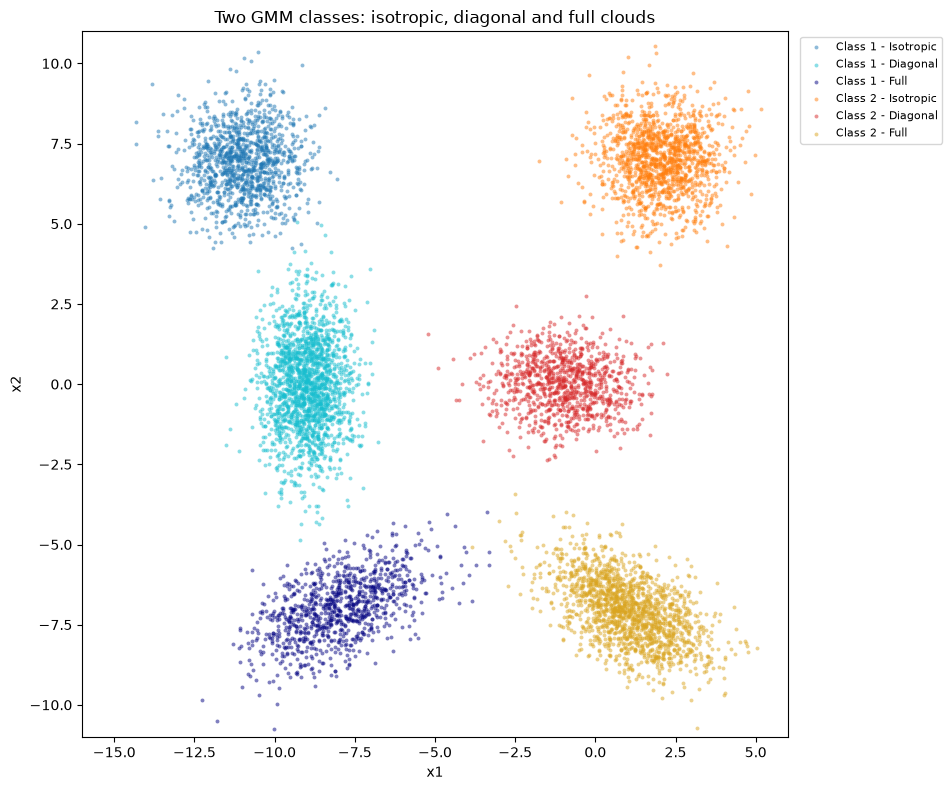

In [15]:
colors = [["tab:blue", "tab:cyan", "navy"], ["tab:orange", "tab:red", "goldenrod"]]
XLIM, YLIM = (-16, 6), (-11, 11)

plt.figure(figsize=(12, 8))
for c in range(2):
    for k in range(K):
        P = class_samples[c][class_labels[c] == k]
        plt.scatter(P[:, 0], P[:, 1], s=8, alpha=0.5, linewidths=0, color=colors[c][k],
                    label=f"Class {c+1} - {cov_names[k]}")
plt.xlim(XLIM); plt.ylim(YLIM); plt.gca().set_aspect("equal")
plt.xlabel("x1"); plt.ylabel("x2")
plt.title("Two GMM classes: isotropic, diagonal and full clouds")
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.tight_layout(); plt.show()

In [16]:
def shuffle(X):
    X = X.copy()
    for i in range(len(X) - 1, 0, -1):             # Fisher-Yates
        j = int(random.random() * (i + 1))
        X[[i, j]] = X[[j, i]]
    return X

def sq_dist(P, centers):
    return ((P[:, None, :] - centers[None]) ** 2).sum(axis=2)

def kmeans(X, K, n_init=10, max_iter=200):
    best = None
    for _ in range(n_init):
        idx = []
        while len(idx) < K:
            j = int(random.random() * len(X))
            if j not in idx:
                idx.append(j)
        centers = X[idx].copy()
        for _ in range(max_iter):
            labels = sq_dist(X, centers).argmin(axis=1)
            new = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centers[k]
                            for k in range(K)])
            if np.allclose(new, centers):
                break
            centers = new
        d = sq_dist(X, centers)
        total = d.min(axis=1).sum()
        if best is None or total < best[0]:
            best = (total, centers, d.argmin(axis=1))
    return best[1], best[2]

train, test, centres, train_clusters = [], [], [], []
cut = int(0.8 * N)
for c in range(2):
    Xs = shuffle(class_samples[c])
    train.append(Xs[:cut]); test.append(Xs[cut:])
    cen, lab = kmeans(Xs[:cut], K)
    centres.append(cen); train_clusters.append(lab)
    print(f"Class {c+1}: {cut} train / {N-cut} test, centres:\n{np.round(cen, 3)}\n")

Class 1: 3200 train / 800 test, centres:
[[-10.997   6.918]
 [ -7.943  -6.88 ]
 [ -8.999  -0.018]]

Class 2: 3200 train / 800 test, centres:
[[ 2.026  6.999]
 [-0.972  0.016]
 [ 1.036 -7.073]]



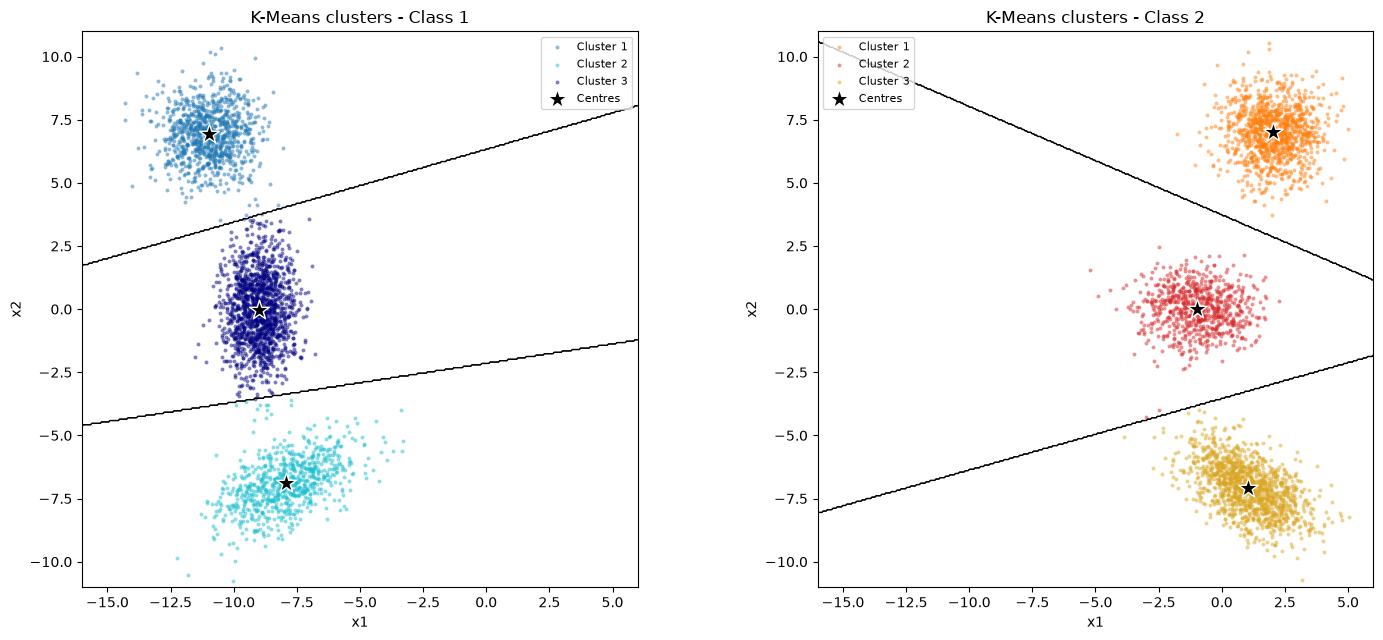

In [17]:
gx, gy = np.meshgrid(np.linspace(*XLIM, 400), np.linspace(*YLIM, 400))
grid = np.column_stack((gx.ravel(), gy.ravel()))

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for c, ax in enumerate(axes):
    gl = sq_dist(grid, centres[c]).argmin(axis=1).reshape(gx.shape)
    for k in range(K):
        P = train[c][train_clusters[c] == k]
        ax.scatter(P[:, 0], P[:, 1], s=8, alpha=0.5, linewidths=0, color=colors[c][k], label=f"Cluster {k+1}")
        ax.contour(gx, gy, (gl == k).astype(float), levels=[0.5], colors="k", linewidths=0.9)
    ax.scatter(centres[c][:, 0], centres[c][:, 1], marker="*", s=220, color="k", edgecolor="w", zorder=5, label="Centres")
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_aspect("equal")
    ax.set_title(f"K-Means clusters - Class {c+1}"); ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [18]:
def distortion(P, cen):
    return sq_dist(P, cen).min(axis=1)

cm = np.zeros((2, 2), dtype=int)                 # rows: true class, cols: predicted class
for true_c in range(2):
    D = np.column_stack([distortion(test[true_c], centres[c]) for c in range(2)])
    for p in D.argmin(axis=1):
        cm[true_c, p] += 1
print("Confusion matrix (rows = true, cols = predicted):\n", cm)
print("Accuracy:", np.trace(cm) / cm.sum())

Confusion matrix (rows = true, cols = predicted):
 [[800   0]
 [  0 800]]
Accuracy: 1.0


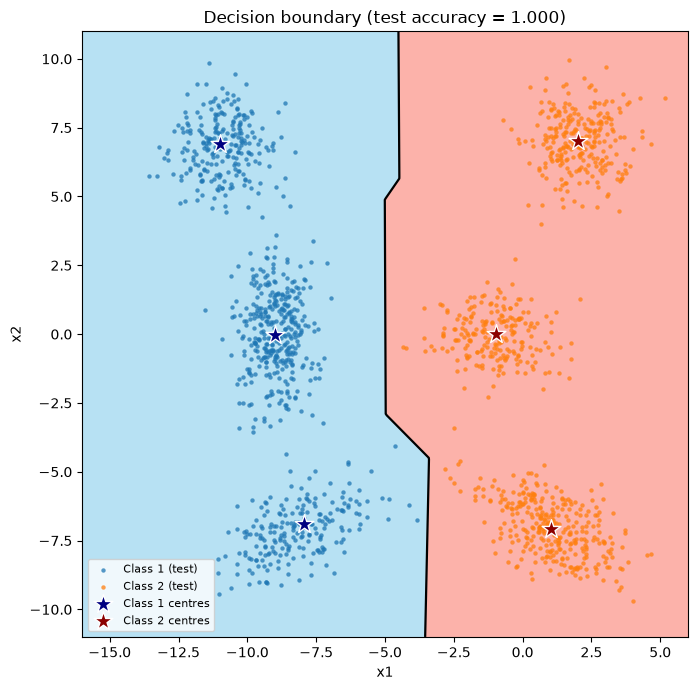

In [19]:
D1 = distortion(grid, centres[0]).reshape(gx.shape)
D2 = distortion(grid, centres[1]).reshape(gx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(gx, gy, D1 - D2, levels=[-1e9, 0, 1e9], colors=["skyblue", "salmon"], alpha=0.6)
plt.contour(gx, gy, D1 - D2, levels=[0], colors="k", linewidths=1.6)
for c in range(2):
    plt.scatter(test[c][:, 0], test[c][:, 1], s=10, alpha=0.75, linewidths=0, color=colors[c][0], label=f"Class {c+1} (test)")
plt.scatter(centres[0][:, 0], centres[0][:, 1], marker="*", s=200, color="navy", edgecolor="w", zorder=5, label="Class 1 centres")
plt.scatter(centres[1][:, 0], centres[1][:, 1], marker="*", s=200, color="darkred", edgecolor="w", zorder=5, label="Class 2 centres")
plt.xlim(XLIM); plt.ylim(YLIM); plt.gca().set_aspect("equal")
plt.xlabel("x1"); plt.ylabel("x2"); plt.title(f"Decision boundary (test accuracy = {np.trace(cm)/cm.sum():.3f})")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()